In [1]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


In [2]:
!kaggle datasets download -d lakshmi25npathi/imdb-dataset-of-50k-movie-reviews

Dataset URL: https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews
License(s): other
100% 25.7M/25.7M [00:00<00:00, 225MB/s]



In [3]:
import zipfile
zip_ref = zipfile.ZipFile('/content/imdb-dataset-of-50k-movie-reviews.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
df = pd.read_csv('/content/IMDB Dataset.csv')
df.shape

(50000, 2)

In [6]:
print(df.info())
print(df.isnull().sum())
print(df.duplicated().sum())
print(df.duplicated().value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB
None
review       0
sentiment    0
dtype: int64
418
False    49582
True       418
Name: count, dtype: int64


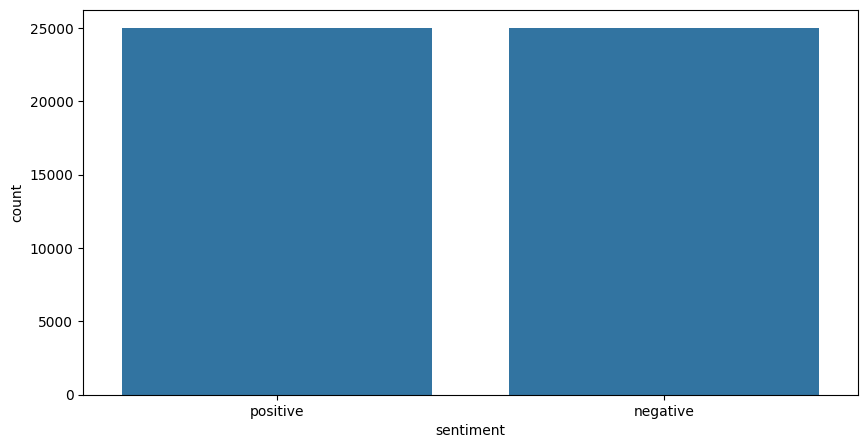

In [7]:
plt.figure(figsize=(10,5))
sns.countplot(x=df['sentiment'])
plt.show()

In [8]:
df['char_count'] = df['review'].apply(lambda x: len(x))
df['word_count'] = df['review'].apply(lambda x: len(x.split()))
df['sentence_count'] = df['review'].apply(lambda x: len(x.split('.')))
df

,review,sentiment,char_count,word_count,sentence_count
0,One of the other reviewers has mentioned that ...,positive,1761,307,27
1,A wonderful little production. <br /><br />The...,positive,998,162,7
2,I thought this was a wonderful way to spend ti...,positive,926,166,7
3,Basically there's a family where a little boy ...,negative,748,138,11
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1317,230,16
...,...,...,...,...,...
49995,I thought this movie did a down right good job...,positive,1008,194,9
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative,642,112,6
49997,I am a Catholic taught in parochial elementary...,negative,1280,230,18
49998,I'm going to have to disagree with the previou...,negative,1234,212,9


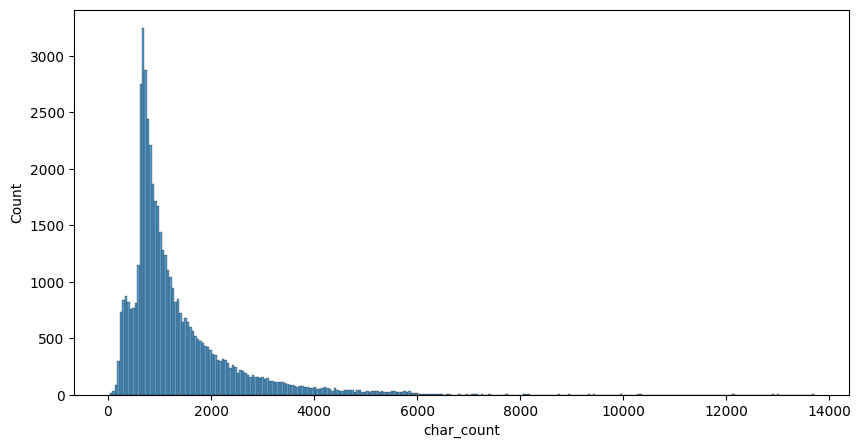

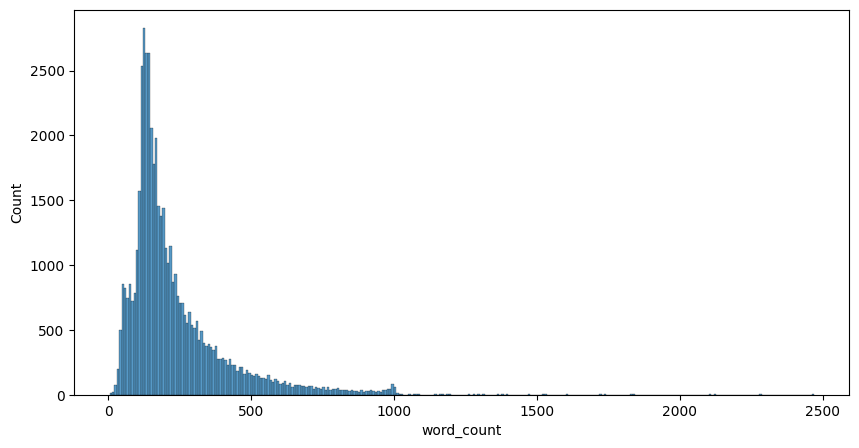

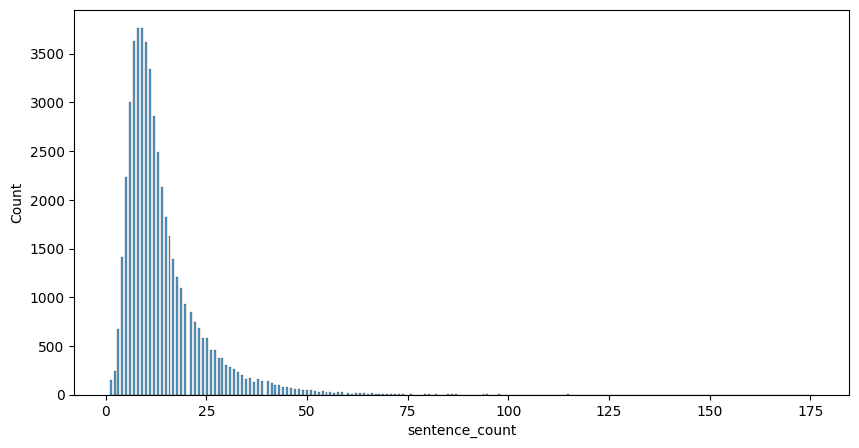

In [9]:
plt.figure(figsize=(10,5))
sns.histplot(df['char_count'])
plt.show()
plt.figure(figsize=(10,5))
sns.histplot(df['word_count'])
plt.show()
plt.figure(figsize=(10,5))
sns.histplot(df['sentence_count'])
plt.show()

In [10]:
# Problem 1

# Apply all the preprocessing techniques that you think are necessary

In [11]:
df['cleaned_review']=df['review'].str.lower()
df.head()

,review,sentiment,char_count,word_count,sentence_count,cleaned_review
0,One of the other reviewers has mentioned that ...,positive,1761,307,27,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,positive,998,162,7,a wonderful little production. <br /><br />the...
2,I thought this was a wonderful way to spend ti...,positive,926,166,7,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,negative,748,138,11,basically there's a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1317,230,16,"petter mattei's ""love in the time of money"" is..."


In [12]:
import re
def remove_html_tags(text):
    pattern = re.compile('<.*?>')
    return pattern.sub(r'', text)
df['cleaned_review'] = df['cleaned_review'].apply(remove_html_tags)
df.head()

,review,sentiment,char_count,word_count,sentence_count,cleaned_review
0,One of the other reviewers has mentioned that ...,positive,1761,307,27,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,positive,998,162,7,a wonderful little production. the filming tec...
2,I thought this was a wonderful way to spend ti...,positive,926,166,7,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,negative,748,138,11,basically there's a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1317,230,16,"petter mattei's ""love in the time of money"" is..."


In [13]:
def remove_url(text):
  pattern=re.compile(r'https?://\S+|www\.\S+')
  return pattern.sub(r'',text)
df['cleaned_review'] = df['cleaned_review'].apply(remove_url)
df.head()

,review,sentiment,char_count,word_count,sentence_count,cleaned_review
0,One of the other reviewers has mentioned that ...,positive,1761,307,27,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,positive,998,162,7,a wonderful little production. the filming tec...
2,I thought this was a wonderful way to spend ti...,positive,926,166,7,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,negative,748,138,11,basically there's a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1317,230,16,"petter mattei's ""love in the time of money"" is..."


In [14]:
import string
def remove_punc(text):
  return text.translate(str.maketrans('','',string.punctuation))
df['cleaned_review'] = df['cleaned_review'].apply(remove_punc)
df.head()

,review,sentiment,char_count,word_count,sentence_count,cleaned_review
0,One of the other reviewers has mentioned that ...,positive,1761,307,27,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,positive,998,162,7,a wonderful little production the filming tech...
2,I thought this was a wonderful way to spend ti...,positive,926,166,7,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,negative,748,138,11,basically theres a family where a little boy j...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1317,230,16,petter matteis love in the time of money is a ...


In [16]:
slang_dict = {}
with open('/content/slang.txt','r') as f:
  for line in f:
    line = line.strip()
    if not line:
      continue
    key,value = line.split('=',1)
    slang_dict[key] = value
print(slang_dict)

{'A3': 'Anytime, Anywhere, Anyplace', 'ADIH': 'Another Day In Hell', 'AFK': 'Away From Keyboard', 'AFAIK': 'As Far As I Know', 'ASAP': 'As Soon As Possible', 'ASL': 'Age, Sex, Location', 'ATK': 'At The Keyboard', 'ATM': 'At The Moment', 'BAE': 'Before Anyone Else', 'BAK': 'Back At Keyboard', 'BBL': 'Be Back Later', 'BBS': 'Be Back Soon', 'BFN': 'Bye For Now', 'B4N': 'Bye For Now', 'BRB': 'Be Right Back', 'BRUH': 'Bro', 'BRT': 'Be Right There', 'BSAAW': 'Big Smile And A Wink', 'BTW': 'By The Way', 'BWL': 'Bursting With Laughter', 'CSL': 'Can’t Stop Laughing', 'CU': 'See You', 'CUL8R': 'See You Later', 'CYA': 'See You', 'DM': 'Direct Message', 'FAQ': 'Frequently Asked Questions', 'FC': 'Fingers Crossed', 'FIMH': 'Forever In My Heart', 'FOMO': 'Fear Of Missing Out', 'FR': 'For Real', 'FWIW': "For What It's Worth", 'FYP': 'For You Page', 'FYI': 'For Your Information', 'G9': 'Genius', 'GAL': 'Get A Life', 'GG': 'Good Game', 'GMTA': 'Great Minds Think Alike', 'GN': 'Good Night', 'GOAT': 'Gre

In [17]:
def replace_slang(text):
  new_text = []
  for word in text.split():
    if word in slang_dict:
      new_text.append(slang_dict[word])
    else:
      new_text.append(word)
  return " ".join(new_text)
df['cleaned_review'] = df['cleaned_review'].apply(replace_slang)
df.head()

,review,sentiment,char_count,word_count,sentence_count,cleaned_review
0,One of the other reviewers has mentioned that ...,positive,1761,307,27,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,positive,998,162,7,a wonderful little production the filming tech...
2,I thought this was a wonderful way to spend ti...,positive,926,166,7,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,negative,748,138,11,basically theres a family where a little boy j...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1317,230,16,petter matteis love in the time of money is a ...


In [31]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

stop_words = set(stopwords.words('english')) - {'not', 'no', 'nor', 'never'}

def remove_stopwords(text):
    new_text = []
    for word in str(text).split():
        if word not in stop_words:
            new_text.append(word)
    return " ".join(new_text)
df['cleaned_review'] = df['cleaned_review'].apply(remove_stopwords)
df

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,review,sentiment,char_count,word_count,sentence_count,cleaned_review
0,One of the other reviewers has mentioned that ...,positive,1761,307,27,one reviewers mentioned watching 1 oz episode ...
1,A wonderful little production. <br /><br />The...,positive,998,162,7,wonderful little production filming technique ...
2,I thought this was a wonderful way to spend ti...,positive,926,166,7,thought wonderful way spend time hot summer we...
3,Basically there's a family where a little boy ...,negative,748,138,11,basically theres family little boy jake thinks...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1317,230,16,petter matteis love time money visually stunni...
...,...,...,...,...,...,...
49995,I thought this movie did a down right good job...,positive,1008,194,9,thought movie right good job wasnt creative or...
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative,642,112,6,bad plot bad dialogue bad acting idiotic direc...
49997,I am a Catholic taught in parochial elementary...,negative,1280,230,18,catholic taught parochial elementary schools n...
49998,I'm going to have to disagree with the previou...,negative,1234,212,9,im going disagree previous comment side maltin...


In [32]:
import nltk
nltk.download('wordnet')
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
def lemmatize_words(text):
  return " ".join([lemmatizer.lemmatize(word) for word in text.split()])
df['cleaned_review'] = df['cleaned_review'].apply(lemmatize_words)
df

[nltk_data] Downloading package wordnet to /root/nltk_data...


,review,sentiment,char_count,word_count,sentence_count,cleaned_review
0,One of the other reviewers has mentioned that ...,positive,1761,307,27,one reviewer mentioned watching 1 oz episode y...
1,A wonderful little production. <br /><br />The...,positive,998,162,7,wonderful little production filming technique ...
2,I thought this was a wonderful way to spend ti...,positive,926,166,7,thought wonderful way spend time hot summer we...
3,Basically there's a family where a little boy ...,negative,748,138,11,basically there family little boy jake think t...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1317,230,16,petter matteis love time money visually stunni...
...,...,...,...,...,...,...
49995,I thought this movie did a down right good job...,positive,1008,194,9,thought movie right good job wasnt creative or...
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative,642,112,6,bad plot bad dialogue bad acting idiotic direc...
49997,I am a Catholic taught in parochial elementary...,negative,1280,230,18,catholic taught parochial elementary school nu...
49998,I'm going to have to disagree with the previou...,negative,1234,212,9,im going disagree previous comment side maltin...


In [33]:
from nltk import word_tokenize, sent_tokenize
nltk.download('punkt_tab')

def word_tokenize(text):
  return nltk.word_tokenize(text)
df['cleaned_review'] = df['cleaned_review'].apply(word_tokenize)
df

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


,review,sentiment,char_count,word_count,sentence_count,cleaned_review
0,One of the other reviewers has mentioned that ...,positive,1761,307,27,"[one, reviewer, mentioned, watching, 1, oz, ep..."
1,A wonderful little production. <br /><br />The...,positive,998,162,7,"[wonderful, little, production, filming, techn..."
2,I thought this was a wonderful way to spend ti...,positive,926,166,7,"[thought, wonderful, way, spend, time, hot, su..."
3,Basically there's a family where a little boy ...,negative,748,138,11,"[basically, there, family, little, boy, jake, ..."
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1317,230,16,"[petter, matteis, love, time, money, visually,..."
...,...,...,...,...,...,...
49995,I thought this movie did a down right good job...,positive,1008,194,9,"[thought, movie, right, good, job, wasnt, crea..."
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative,642,112,6,"[bad, plot, bad, dialogue, bad, acting, idioti..."
49997,I am a Catholic taught in parochial elementary...,negative,1280,230,18,"[catholic, taught, parochial, elementary, scho..."
49998,I'm going to have to disagree with the previou...,negative,1234,212,9,"[im, going, disagree, previous, comment, side,..."


In [34]:
df['cleaned_review'] = df['cleaned_review'].apply(lambda s: ' '.join(s) if isinstance(s, list) else s)
print(type(df['cleaned_review'].iloc[0]))


<class 'str'>


In [35]:
# Problem 2

# Find out the number of words in the entire corpus and also the total number of unique words(vocabulary) using just python

In [36]:
total_words = df['cleaned_review'].apply(len).sum()
print(total_words)

41546557


In [37]:
unique_words = len(set(word for tokens in df['cleaned_review'] for word in tokens))
print(unique_words)

127


In [38]:
# Problem 3

# Apply One Hot Encoding

In [39]:
sentences = df['cleaned_review'].head(3).tolist()
print(sentences)

['one reviewer mentioned watching 1 oz episode youll hooked right exactly happened methe first thing struck oz brutality unflinching scene violence set right word go trust not show faint hearted timid show pull no punch regard drug sex violence hardcore classic use wordit called oz nickname given oswald maximum security state penitentary focus mainly emerald city experimental section prison cell glass front face inwards privacy not high agenda em city home manyaryans muslim gangsta latino christian italian irish moreso scuffle death stare dodgy dealing shady agreement never far awayi would say main appeal show due fact go show wouldnt dare forget pretty picture painted mainstream audience forget charm forget romanceoz doesnt mess around first episode ever saw struck nasty surreal couldnt say ready watched developed taste oz got accustomed high level graphic violence not violence injustice crooked guard wholl sold nickel inmate wholl kill order get away well mannered middle class inmate

In [40]:
vocab = sorted(set(word for sent in sentences for word in str(sent).split()))
word_to_index = {word:i for i,word in enumerate(vocab)}
print('Vocabulary Size ', len(vocab))
print(vocab)

Vocabulary Size  278
['1', '2', 'accustomed', 'actor', 'addiction', 'agenda', 'agreement', 'air', 'allen', 'appeal', 'around', 'audience', 'average', 'away', 'awayi', 'become', 'bitch', 'bread', 'brutality', 'called', 'career', 'cell', 'character', 'charm', 'chosen', 'christian', 'city', 'class', 'classic', 'come', 'comedy', 'comfortable', 'comforting', 'concerning', 'conditioned', 'control', 'couldnt', 'crooked', 'crown', 'dare', 'darker', 'dealing', 'death', 'decade', 'decorating', 'developed', 'devil', 'dialogue', 'diary', 'disappears', 'disappointed', 'discomforting', 'dodgy', 'doesnt', 'done', 'dream', 'drug', 'due', 'editing', 'em', 'emerald', 'entire', 'entry', 'episode', 'even', 'ever', 'every', 'exactly', 'experience', 'experimental', 'extremely', 'face', 'fact', 'faint', 'fantasy', 'far', 'fashion', 'filming', 'first', 'flat', 'focus', 'forget', 'friend', 'front', 'fully', 'gangsta', 'get', 'give', 'given', 'glass', 'go', 'got', 'graphic', 'great', 'grown', 'guard', 'guided',

In [41]:
def one_hot_encode(sentence):
  vectors = []
  for word in str(sentence).split():
    v = np.zeros(len(vocab))
    v[word_to_index[word]] = 1
    vectors.append(v)
  return np.array(vectors)
result = one_hot_encode(sentences[0])
print(result)
print(result.shape)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
(172, 278)


In [42]:
# Problem 4

# Apply bag words and find the vocabulary also find the times each word has occured

In [43]:
df['cleaned_review'] = df['cleaned_review'].apply(lambda s: ' '.join(s) if isinstance(s, list) else s)
print(type(df['cleaned_review'].iloc[0]))


<class 'str'>


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(max_features=5000)
bow = cv.fit_transform(df['cleaned_review'])
bow[0].toarray()
print(cv.get_feature_names_out()[:10])
print(bow.shape)
print(type(bow))
cv.vocabulary_

In [45]:
cv.transform(['this is a good movie']).toarray()

array([[0, 0, 0, ..., 0, 0, 0]], shape=(1, 5000))

In [46]:
words = ['this', 'is', 'a', 'good', 'movie']

for word in words:
    print(word, word in cv.vocabulary_)

this False
is False
a False
good True
movie True


In [50]:
words = cv.get_feature_names_out()
counts = np.asarray(bow.sum(axis=0)).ravel()
word_counts = pd.DataFrame({'word': words, 'count': counts})
word_counts = word_counts.sort_values(by='count', ascending=False)
word_counts.head(20)

,word,count
2918,movie,98946
1721,film,89762
3048,not,61604
3111,one,52653
2608,like,39785
4516,time,29358
1938,good,28596
752,character,27568
1903,get,24432
1544,even,24286


In [ ]:
# Problem 5

# Apply bag of bi-gram and bag of tri-gram and write down your observation about the dimensionality of the vocabulary

In [53]:

from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(ngram_range=(2,2))
bi_gram = cv.fit_transform(df['cleaned_review'])
print(cv.get_feature_names_out()[:10])
print(bi_gram.shape)      # Dimensionality of Vocabulary
bi_gram[0].toarray()


['00 acting' '00 agent' '00 come' '00 including' '00 schneider' '00 worth'
 '000 000' '000 overboard' '000 produce' '0000000000001 10']
(50000, 3104623)


array([[0, 0, 0, ..., 0, 0, 0]], shape=(1, 3104623))

In [54]:
cv = CountVectorizer(ngram_range=(3,3))
tri_gram = cv.fit_transform(df['cleaned_review'])
print(cv.get_feature_names_out()[:10])
tri_gram[0].toarray()


['00 acting character' '00 agent difficult' '00 agent level'
 '00 come back' '00 including unusual' '00 schneider directly'
 '00 schneider murderervillain' '00 worth film' '000 000 overboard'
 '000 produce movie']


array([[0, 0, 0, ..., 0, 0, 0]], shape=(1, 5465210))

In [56]:
# Problem 6

# Apply tf-idf and find out the idf scores of words, also find out the vocabulary.

In [57]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(df['cleaned_review'])
print(tfidf.get_feature_names_out())
print(tfidf_matrix.shape)


['00' '000' '0000000000001' ... 'þór' 'יגאל' 'כרמון']
(50000, 210262)


In [61]:
words = tfidf.get_feature_names_out()
idf_score= tfidf.idf_
idf_scores = pd.DataFrame({'word': words, 'idf_score': idf_score})
idf_scores = idf_scores.sort_values(by='idf_score', ascending=False)
idf_scores.head(20)

,word,idf_score
5,0001,11.126651
210261,כרמון,11.126651
210260,יגאל,11.126651
6,00015,11.126651
2,0000000000001,11.126651
3,00000001,11.126651
210243,úbercrap,11.126651
210242,østbye,11.126651
210241,özdemir,11.126651
210240,örnek,11.126651


In [65]:
idf_scores.sort_values(
    by='idf_score',
    ascending=True
).head(20)


,word,idf_score
122600,movie,1.448153
129356,not,1.514419
68502,film,1.554101
132631,one,1.576345
107982,like,1.775028
187418,time,1.949816
78802,good,1.991627
112615,make,2.104691
162974,see,2.112630
62521,even,2.113056


In [74]:
idf_scores[idf_scores['word'] == 'freeze']

,word,idf_score
73284,freeze,7.319989
